# Tahap 4 — Evaluasi Model: EfficientNet-B0

Notebook ini mengevaluasi model **EfficientNet-B0 hasil training** di `train_efficientnet.ipynb`.
Bobot terbaik dimuat dari checkpoint `models/efficientnet_b0_best.pt`, lalu model diuji ulang langsung
pada validation dan test set. Tidak ada training di sini.

Yang dievaluasi:
1. Ringkasan proses training (kurva belajar dari history)
2. Metrik keseluruhan — accuracy, precision, recall, F1, top-k — beserta selang kepercayaannya
3. Kinerja per kelas dan confusion matrix
4. Kalibrasi confidence — apakah model tahu kapan ia ragu
5. Visualisasi prediksi dan analisis kesalahan
6. Efisiensi komputasi

**Prasyarat:** `train_efficientnet.ipynb` (atau `python train_efficientnet.py`) sudah dijalankan.

Grafik disimpan ke `results/efficientnet_b0/evaluation/` agar bisa langsung dipakai di laporan.

## 1. Setup & Memuat Model

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.ticker import MaxNLocator
from PIL import Image
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support, top_k_accuracy_score)

import data_pipeline as dp
import training as tr

MODEL_NAME = "efficientnet_b0"

# Palet sama dengan notebook training: biru = train, oranye = validation
C_TRAIN, C_VAL = "#2a78d6", "#eb6834"
C_OK, C_SALAH = "#1baf7a", "#eb6834"
C_GRID, C_TEXT = "#d8d7d2", "#52514e"
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True, "grid.color": C_GRID, "grid.linewidth": 0.6,
    "axes.edgecolor": C_GRID, "axes.labelcolor": C_TEXT,
    "xtick.color": C_TEXT, "ytick.color": C_TEXT,
    "axes.spines.top": False, "axes.spines.right": False,
})

OUT_DIR = tr.RESULT_DIR / MODEL_NAME / "evaluation"
OUT_DIR.mkdir(parents=True, exist_ok=True)

def simpan(fig, nama):
    fig.savefig(OUT_DIR / f"{nama}.png", dpi=150, bbox_inches="tight")

dp.seed_everything(dp.SEED)
DEVICE = dp.get_device()

ckpt_path = tr.MODEL_DIR / f"{MODEL_NAME}_best.pt"
ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
CONFIG = tr.TrainConfig(**ckpt["config"])
CLASSES = ckpt["classes"]

model = tr.build_model(MODEL_NAME, num_classes=len(CLASSES), pretrained=False)
model.load_state_dict(ckpt["model_state"])
model = model.to(DEVICE).eval()

history = json.loads((tr.RESULT_DIR / MODEL_NAME / "history.json").read_text())

print(f"Device      : {DEVICE}")
print(f"Checkpoint  : {ckpt_path.name}")
print(f"  diambil dari epoch {ckpt['epoch']} (val macro-F1 {ckpt['val_macro_f1']:.4f})")
print(f"Kelas       : {len(CLASSES)}")
print(f"Konfigurasi : epochs={CONFIG.epochs}, lr={CONFIG.lr}, batch={CONFIG.batch_size}, "
      f"augment={CONFIG.augment}, class_weights={CONFIG.use_class_weights}")

Device      : mps
Checkpoint  : efficientnet_b0_best.pt
  diambil dari epoch 5 (val macro-F1 0.9217)
Kelas       : 31
Konfigurasi : epochs=5, lr=0.0001, batch=32, augment=basic, class_weights=True


In [2]:
# Augmentasi hanya dipakai di split train; val & test selalu resize + center crop
# + normalisasi, jadi evaluasi di bawah deterministik.
loaders, ds = dp.build_dataloaders(batch_size=CONFIG.batch_size, num_workers=2, augment=CONFIG.augment)
assert ds["train"].classes == CLASSES, "Urutan kelas dataset berbeda dengan checkpoint"
print(f"val  : {len(ds['val'])} citra")
print(f"test : {len(ds['test'])} citra")

val  : 905 citra
test : 905 citra


## 2. Ringkasan Proses Training

Sebelum melihat skor test, pastikan dulu proses training-nya sehat: loss turun, tidak overfitting,
dan checkpoint yang dipakai memang epoch terbaik menurut validation.

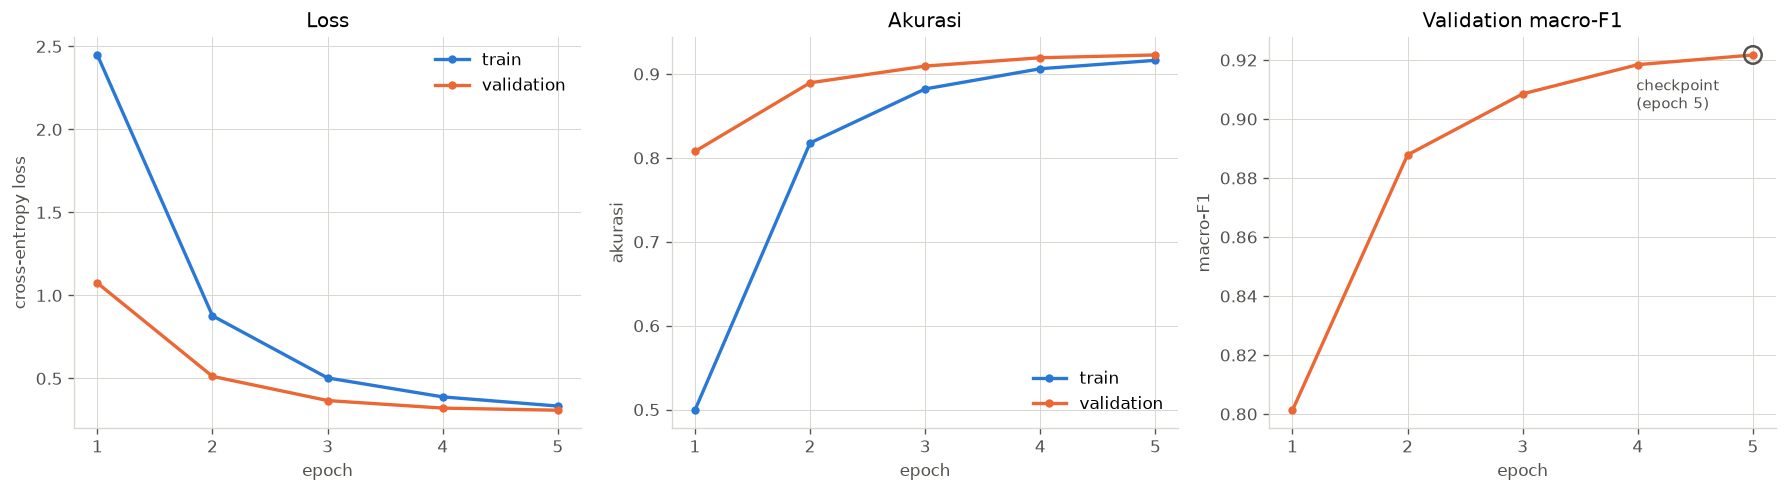

Epoch dijalankan        : 5
Epoch terbaik (val F1)  : 5
Gap train-val akurasi   : -0.0064  (> +0.10 = overfitting)
Kenaikan val F1 terakhir: +0.0033

Catatan: epoch terbaik = epoch terakhir -> model belum sepenuhnya konvergen; dengan epoch lebih banyak skornya kemungkinan masih bisa naik.


In [3]:
hist = pd.DataFrame(history)
best_ep = int(ckpt["epoch"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].plot(hist["epoch"], hist["train_loss"], color=C_TRAIN, lw=2, marker="o", ms=4, label="train")
axes[0].plot(hist["epoch"], hist["val_loss"], color=C_VAL, lw=2, marker="o", ms=4, label="validation")
axes[0].set(title="Loss", ylabel="cross-entropy loss")
axes[1].plot(hist["epoch"], hist["train_acc"], color=C_TRAIN, lw=2, marker="o", ms=4, label="train")
axes[1].plot(hist["epoch"], hist["val_acc"], color=C_VAL, lw=2, marker="o", ms=4, label="validation")
axes[1].set(title="Akurasi", ylabel="akurasi")
axes[2].plot(hist["epoch"], hist["val_macro_f1"], color=C_VAL, lw=2, marker="o", ms=4)
axes[2].scatter([best_ep], [ckpt["val_macro_f1"]], s=110, facecolor="none",
                edgecolor=C_TEXT, lw=1.5, zorder=5)
axes[2].annotate(f"checkpoint\n(epoch {best_ep})", xy=(best_ep, ckpt["val_macro_f1"]),
                 xytext=(-70, -32), textcoords="offset points", fontsize=9, color=C_TEXT)
axes[2].set(title="Validation macro-F1", ylabel="macro-F1")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].legend(frameon=False)
axes[1].legend(frameon=False)
plt.tight_layout()
simpan(fig, "kurva_belajar")
plt.show()

hb = hist.loc[hist["epoch"] == best_ep].iloc[0]
print(f"Epoch dijalankan        : {len(hist)}")
print(f"Epoch terbaik (val F1)  : {best_ep}")
print(f"Gap train-val akurasi   : {hb['train_acc'] - hb['val_acc']:+.4f}  (> +0.10 = overfitting)")
print(f"Kenaikan val F1 terakhir: {hist['val_macro_f1'].diff().iloc[-1]:+.4f}")
if best_ep == len(hist):
    print("\nCatatan: epoch terbaik = epoch terakhir -> model belum sepenuhnya konvergen; "
          "dengan epoch lebih banyak skornya kemungkinan masih bisa naik.")

## 3. Prediksi pada Validation & Test Set

Model dijalankan ulang pada kedua split. Validation dipakai saat training untuk memilih checkpoint,
jadi skornya sedikit optimistis; **test set adalah estimasi jujur** kinerja model pada data baru karena
tidak pernah dipakai untuk mengambil keputusan apa pun selama training.

In [4]:
t0 = time.perf_counter()
pred = {}
for split in ["val", "test"]:
    probs, preds, trues = tr.predict(model, loaders[split], DEVICE)
    pred[split] = {"probs": probs, "preds": preds, "trues": trues}
print(f"Prediksi selesai dalam {time.perf_counter() - t0:.1f} detik\n")

def ringkas(split):
    p = pred[split]
    pm, rm, fm, _ = precision_recall_fscore_support(p["trues"], p["preds"], average="macro", zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(p["trues"], p["preds"], average="weighted", zero_division=0)
    lab = range(len(CLASSES))
    return {
        "accuracy": accuracy_score(p["trues"], p["preds"]),
        "top3_accuracy": top_k_accuracy_score(p["trues"], p["probs"], k=3, labels=lab),
        "top5_accuracy": top_k_accuracy_score(p["trues"], p["probs"], k=5, labels=lab),
        "precision_macro": pm, "recall_macro": rm, "f1_macro": fm,
        "precision_weighted": pw, "recall_weighted": rw, "f1_weighted": fw,
        "n_citra": len(p["trues"]), "n_salah": int((p["preds"] != p["trues"]).sum()),
    }

metrik = pd.DataFrame({s: ringkas(s) for s in ["val", "test"]})
metrik["selisih (test-val)"] = metrik["test"] - metrik["val"]
print(metrik.to_string(float_format=lambda v: f"{v:.4f}"))
metrik.to_csv(OUT_DIR / "metrik_val_test.csv")

# Sanity check: harus identik dengan hasil tr.evaluate() di notebook training
tersimpan = json.loads((tr.RESULT_DIR / MODEL_NAME / "metrics.json").read_text())
cocok = abs(tersimpan["accuracy"] - metrik.loc["accuracy", "test"]) < 1e-9
print(f"\nCocok dengan results/{MODEL_NAME}/metrics.json: {'ya' if cocok else 'TIDAK — cek checkpoint/split'}")

Prediksi selesai dalam 24.7 detik



                        val     test  selisih (test-val)
accuracy             0.9227   0.9403              0.0177
top3_accuracy        0.9845   0.9856              0.0011
top5_accuracy        0.9912   0.9923              0.0011
precision_macro      0.9257   0.9412              0.0156
recall_macro         0.9220   0.9402              0.0182
f1_macro             0.9217   0.9394              0.0177
precision_weighted   0.9260   0.9425              0.0165
recall_weighted      0.9227   0.9403              0.0177
f1_weighted          0.9222   0.9401              0.0180
n_citra            905.0000 905.0000              0.0000
n_salah             70.0000  54.0000            -16.0000

Cocok dengan results/efficientnet_b0/metrics.json: ya


### 3.1 Selang Kepercayaan (Bootstrap)

Test set berisi 905 citra; satu citra = 0.11% akurasi. Angka akurasi adalah estimasi dari sampel itu,
bukan nilai pasti. Bootstrap (resample test set 2000 kali) memberi rentang yang wajar untuk dilaporkan,
misalnya "akurasi 94.0% (95% CI 92.5–95.6%)".

In [5]:
P = pred["test"]
trues, preds, probs = P["trues"], P["preds"], P["probs"]
n_test = len(trues)

B = 2000
rng = np.random.default_rng(dp.SEED)
boot = {"accuracy": [], "precision_macro": [], "recall_macro": [], "f1_macro": []}
for _ in range(B):
    ii = rng.integers(0, n_test, n_test)
    pm, rm, fm, _ = precision_recall_fscore_support(trues[ii], preds[ii], average="macro",
                                                     labels=range(len(CLASSES)), zero_division=0)
    boot["accuracy"].append((trues[ii] == preds[ii]).mean())
    boot["precision_macro"].append(pm)
    boot["recall_macro"].append(rm)
    boot["f1_macro"].append(fm)

ci = pd.DataFrame([
    {"metrik": k, "nilai": metrik.loc[k, "test"],
     "ci_95_bawah": np.percentile(v, 2.5), "ci_95_atas": np.percentile(v, 97.5)}
    for k, v in boot.items()
])
print(ci.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
ci.to_csv(OUT_DIR / "bootstrap_ci.csv", index=False)

         metrik  nilai  ci_95_bawah  ci_95_atas
       accuracy 0.9403       0.9249      0.9558
precision_macro 0.9412       0.9259      0.9561
   recall_macro 0.9402       0.9251      0.9555
       f1_macro 0.9394       0.9231      0.9538


## 4. Kinerja per Kelas

In [6]:
print(classification_report(trues, preds, target_names=CLASSES, digits=4, zero_division=0))

p_c, r_c, f_c, s_c = precision_recall_fscore_support(trues, preds, labels=range(len(CLASSES)),
                                                     zero_division=0)
per_kelas = pd.DataFrame({"kelas": CLASSES, "precision": p_c, "recall": r_c, "f1": f_c,
                          "support": s_c, "n_train": dp.class_counts(ds["train"])})
per_kelas.to_csv(OUT_DIR / "per_kelas.csv", index=False)

               precision    recall  f1-score   support

         adas     1.0000    0.8966    0.9455        29
    andaliman     1.0000    0.8966    0.9455        29
    asam jawa     0.8500    0.9444    0.8947        18
bawang bombai     1.0000    1.0000    1.0000        31
 bawang merah     0.9394    1.0000    0.9688        31
 bawang putih     0.9677    1.0000    0.9836        30
biji ketumbar     0.8065    0.8929    0.8475        28
 bukan rempah     0.9062    0.9355    0.9206        31
 bunga lawang     0.9062    1.0000    0.9508        29
      cengkeh     1.0000    0.9630    0.9811        27
   daun jeruk     0.9355    1.0000    0.9667        29
 daun kemangi     0.9355    0.9355    0.9355        31
daun ketumbar     0.9667    1.0000    0.9831        29
   daun salam     1.0000    0.9310    0.9643        29
         jahe     1.0000    0.9655    0.9825        29
       jinten     0.8571    0.9231    0.8889        26
     kapulaga     0.8929    0.8065    0.8475        31
   kayu m

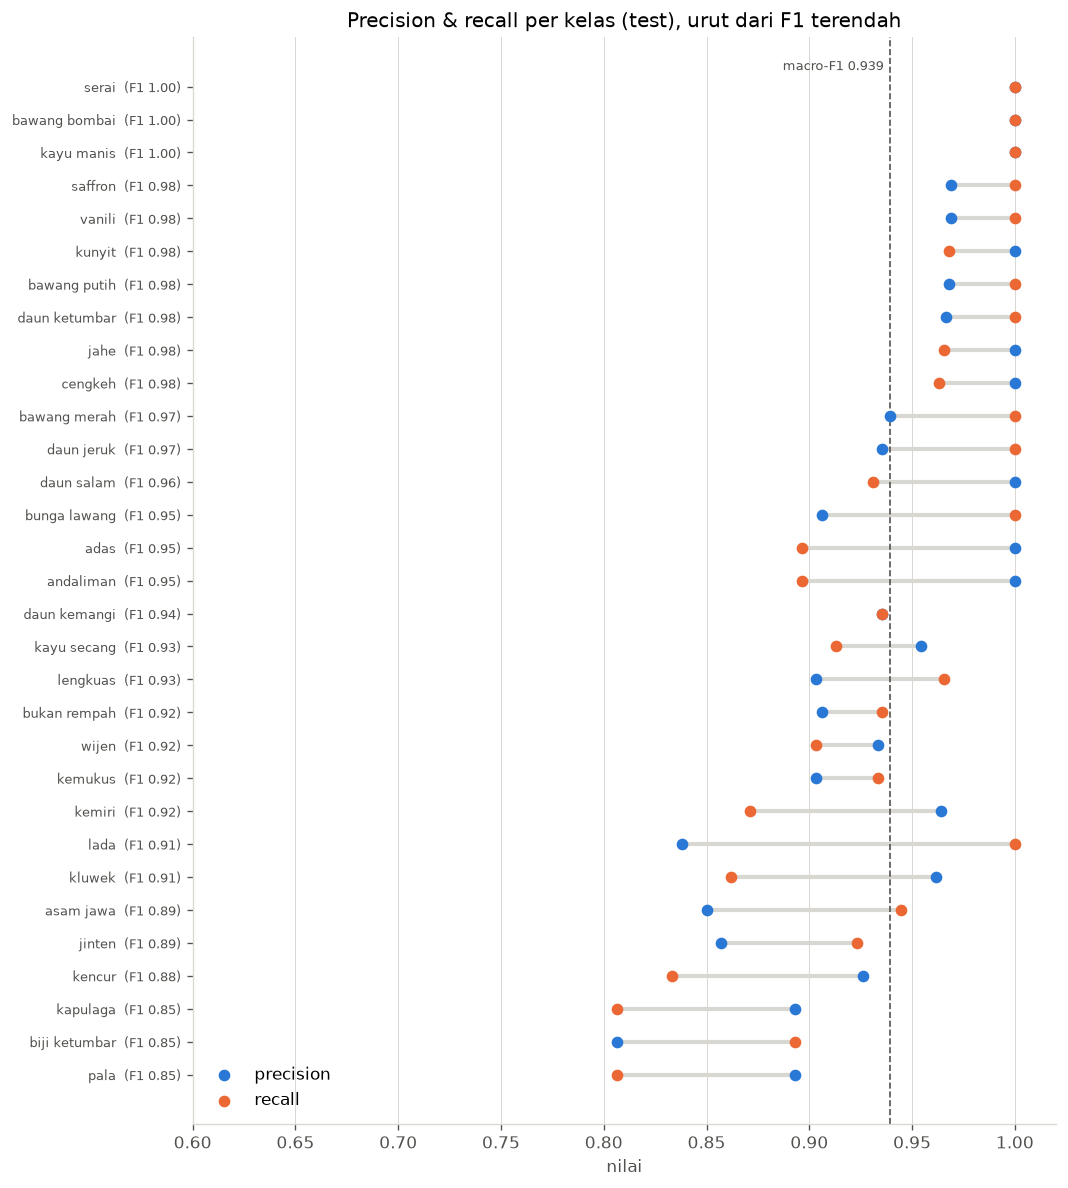

Cara membaca: recall < precision -> citra kelas itu sering diprediksi sebagai kelas lain;
precision < recall -> kelas lain sering 'masuk' ke kelas itu.

5 kelas terlemah:
        kelas  precision  recall     f1  support  n_train
         pala     0.8929  0.8065 0.8475       31      144
biji ketumbar     0.8065  0.8929 0.8475       28      132
     kapulaga     0.8929  0.8065 0.8475       31      141
       kencur     0.9259  0.8333 0.8772       30      141
       jinten     0.8571  0.9231 0.8889       26      120

Catatan: tiap kelas hanya ~29 citra test, jadi 1 citra salah ≈ 3% recall. Selisih kecil antar kelas jangan terlalu ditafsirkan.


In [7]:
pk = per_kelas.sort_values("f1").reset_index(drop=True)
y = np.arange(len(pk))

fig, ax = plt.subplots(figsize=(9, 10))
# Precision & recall sebagai dua titik per kelas: jarak keduanya menunjukkan jenis kesalahannya
ax.hlines(y, pk[["precision", "recall"]].min(axis=1), pk[["precision", "recall"]].max(axis=1),
          color=C_GRID, lw=2.5, zorder=1)
ax.scatter(pk["precision"], y, color=C_TRAIN, s=36, zorder=3, label="precision")
ax.scatter(pk["recall"], y, color=C_VAL, s=36, zorder=3, label="recall")
ax.set_yticks(y)
ax.set_yticklabels([f"{k}  (F1 {f:.2f})" for k, f in zip(pk["kelas"], pk["f1"])], fontsize=8)
f1m = metrik.loc["f1_macro", "test"]
ax.axvline(f1m, color=C_TEXT, lw=1, ls="--")
ax.annotate(f"macro-F1 {f1m:.3f}", xy=(f1m, len(pk) - 0.5), xytext=(-4, 0),
            textcoords="offset points", ha="right", fontsize=8, color=C_TEXT)
ax.set(xlabel="nilai", xlim=(min(0.6, pk[["precision", "recall"]].min().min() - 0.02), 1.02),
       title="Precision & recall per kelas (test), urut dari F1 terendah")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
simpan(fig, "precision_recall_per_kelas")
plt.show()

print("Cara membaca: recall < precision -> citra kelas itu sering diprediksi sebagai kelas lain;")
print("precision < recall -> kelas lain sering 'masuk' ke kelas itu.\n")
print("5 kelas terlemah:")
print(pk.head(5).round(4).to_string(index=False))
print(f"\nCatatan: tiap kelas hanya ~{int(s_c.mean())} citra test, jadi 1 citra salah ≈ "
      f"{1 / s_c.mean():.0%} recall. Selisih kecil antar kelas jangan terlalu ditafsirkan.")

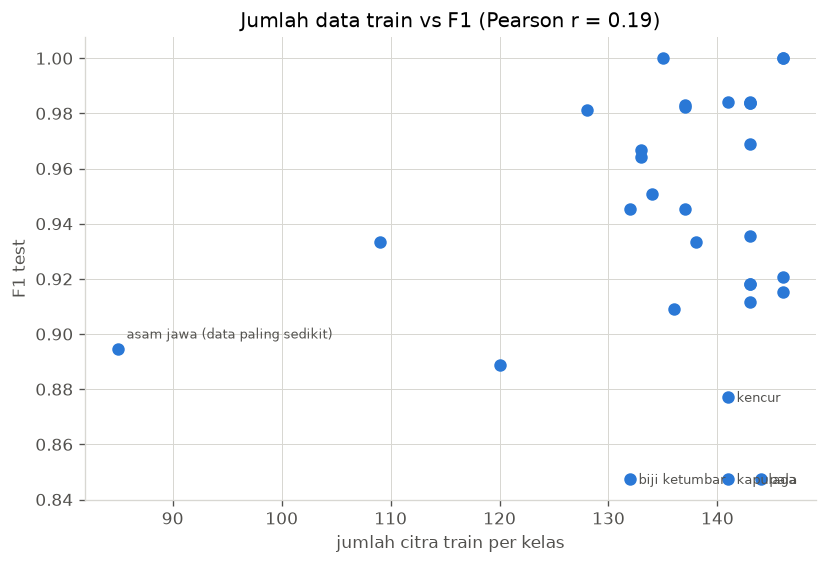

r = 0.19: lemah — kesulitan kelas lebih ditentukan kemiripan visual daripada jumlah data.


In [8]:
# Apakah kelas dengan data train lebih sedikit lebih sulit?
fig, ax = plt.subplots(figsize=(7, 4.8))
ax.scatter(per_kelas["n_train"], per_kelas["f1"], color=C_TRAIN, s=42, zorder=3)
for r in per_kelas.nsmallest(4, "f1").itertuples():
    ax.annotate(r.kelas, xy=(r.n_train, r.f1), xytext=(5, -3), textcoords="offset points",
                fontsize=8, color=C_TEXT)
kecil = per_kelas.loc[per_kelas["n_train"].idxmin()]
ax.annotate(f"{kecil['kelas']} (data paling sedikit)", xy=(kecil["n_train"], kecil["f1"]),
            xytext=(5, 6), textcoords="offset points", fontsize=8, color=C_TEXT)
r_data = per_kelas["n_train"].corr(per_kelas["f1"])
ax.set(xlabel="jumlah citra train per kelas", ylabel="F1 test",
       title=f"Jumlah data train vs F1 (Pearson r = {r_data:.2f})")
plt.tight_layout()
simpan(fig, "data_train_vs_f1")
plt.show()
print(f"r = {r_data:.2f}: " + ("lemah — kesulitan kelas lebih ditentukan kemiripan visual daripada jumlah data."
                               if abs(r_data) < 0.3 else "jumlah data ikut memengaruhi kinerja kelas."))

## 5. Confusion Matrix

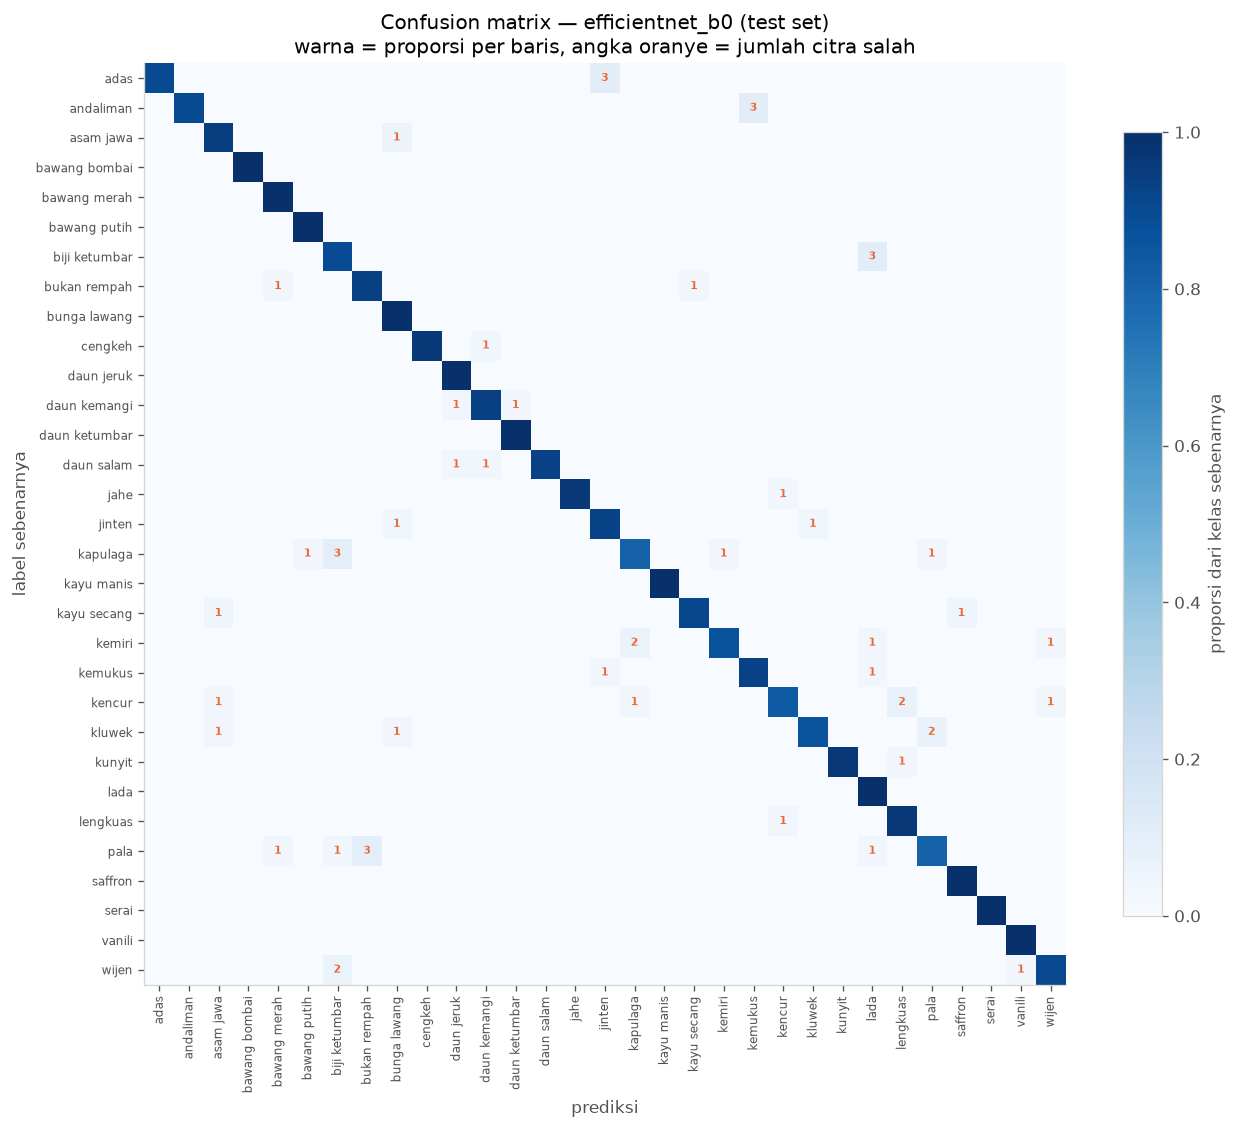

Pasangan kelas paling sering tertukar:
   sebenarnya    diprediksi  n  proporsi
         adas        jinten  3     0.103
     kapulaga biji ketumbar  3     0.097
biji ketumbar          lada  3     0.107
         pala  bukan rempah  3     0.097
    andaliman       kemukus  3     0.103
        wijen biji ketumbar  2     0.065
       kluwek          pala  2     0.069
       kencur      lengkuas  2     0.067
       kemiri      kapulaga  2     0.065
   daun salam    daun jeruk  1     0.034
       kencur     asam jawa  1     0.033
    asam jawa  bunga lawang  1     0.056

Tertukar DUA ARAH: kapulaga<->kemiri, kencur<->lengkuas
Total salah: 54 dari 905 citra test


In [9]:
cm = confusion_matrix(trues, preds, labels=range(len(CLASSES)))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES))); ax.set_yticks(range(len(CLASSES)))
ax.set_xticklabels(CLASSES, rotation=90, fontsize=7)
ax.set_yticklabels(CLASSES, fontsize=7)
# Angka hanya di sel salah-klasifikasi, agar mata langsung ke kesalahan
for i, j in zip(*np.nonzero(cm)):
    if i != j:
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6.5,
                color=C_SALAH, fontweight="bold")
ax.set(xlabel="prediksi", ylabel="label sebenarnya",
       title=f"Confusion matrix — {MODEL_NAME} (test set)\n"
             "warna = proporsi per baris, angka oranye = jumlah citra salah")
ax.grid(visible=False)
fig.colorbar(im, ax=ax, shrink=0.8).set_label("proporsi dari kelas sebenarnya", color=C_TEXT)
plt.tight_layout()
simpan(fig, "confusion_matrix")
plt.show()

salah = [(CLASSES[i], CLASSES[j], int(cm[i, j]), cm_norm[i, j])
         for i, j in zip(*np.nonzero(cm)) if i != j]
konfusi = pd.DataFrame(salah, columns=["sebenarnya", "diprediksi", "n", "proporsi"]) \
    .sort_values("n", ascending=False)
print("Pasangan kelas paling sering tertukar:")
print(konfusi.head(12).round(3).to_string(index=False))

# Pasangan yang tertukar dua arah = kedua kelas memang sulit dibedakan
pasangan = set(zip(konfusi["sebenarnya"], konfusi["diprediksi"]))
dua_arah = sorted({tuple(sorted(p)) for p in pasangan if (p[1], p[0]) in pasangan})
print(f"\nTertukar DUA ARAH: {', '.join(f'{a}<->{b}' for a, b in dua_arah) or '-'}")
print(f"Total salah: {int(cm.sum() - np.trace(cm))} dari {int(cm.sum())} citra test")

## 6. Kalibrasi Confidence

Akurasi saja tidak memberi tahu apakah **confidence** model bisa dipercaya. Model yang terkalibrasi baik:
kalau ia bilang yakin 90%, ia benar sekitar 90% dari waktu. Ini penting kalau model dipakai di aplikasi —
prediksi dengan confidence rendah bisa ditandai "tidak yakin" alih-alih langsung ditampilkan.

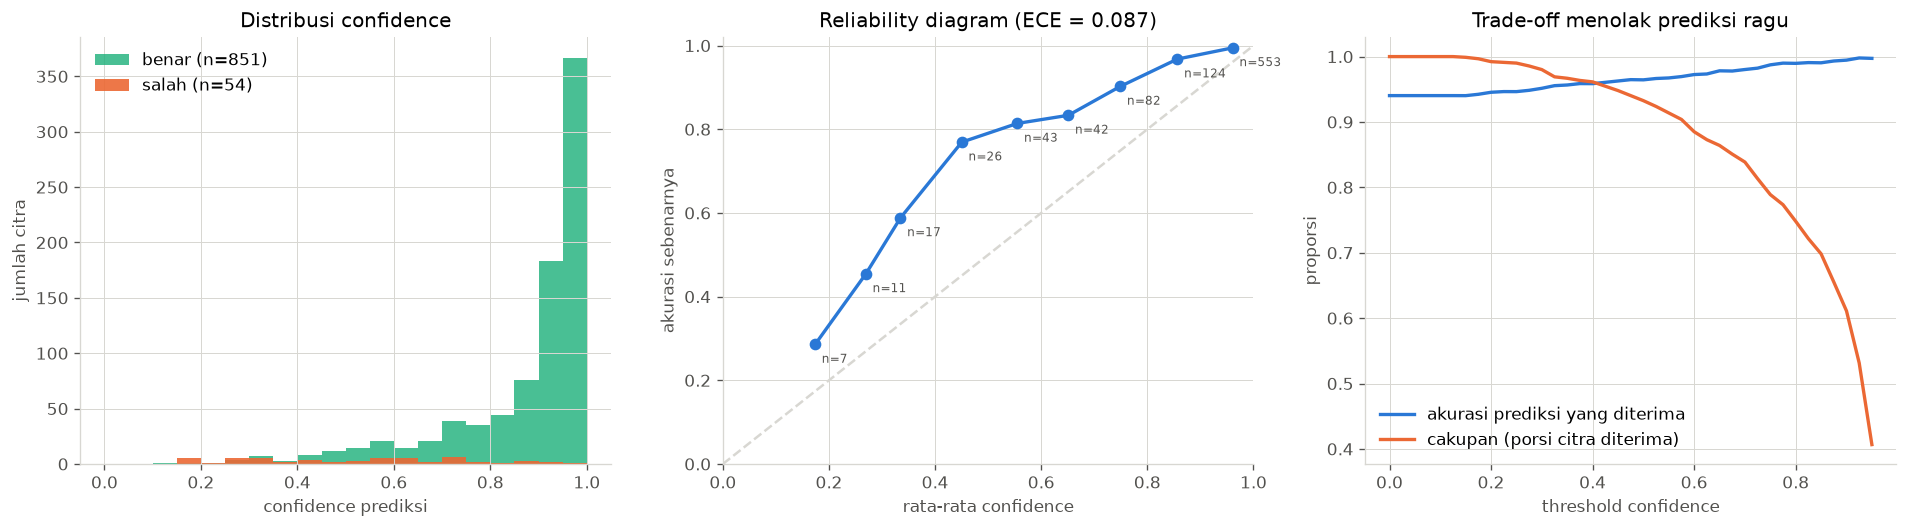

Rata-rata confidence saat BENAR: 0.8734
Rata-rata confidence saat SALAH: 0.5291
ECE: 0.0875  (0 = sempurna; < 0.05 umumnya dianggap terkalibrasi baik)
Kecenderungan: underconfident (lebih sering benar daripada yang diklaim confidence-nya) — rata-rata confidence 0.853 vs akurasi 0.940
  threshold 0.5:  93.3% citra diterima, akurasinya 96.45%
  threshold 0.7:  83.9% citra diterima, akurasinya 98.02%
  threshold 0.9:  61.1% citra diterima, akurasinya 99.46%


In [10]:
conf = probs[np.arange(n_test), preds]
benar = preds == trues

# Reliability diagram + Expected Calibration Error (ECE)
bins = np.linspace(0, 1, 11)
idx_bin = np.clip(np.digitize(conf, bins) - 1, 0, 9)
rel = pd.DataFrame({"bin": idx_bin, "conf": conf, "benar": benar}).groupby("bin") \
    .agg(conf=("conf", "mean"), akurasi=("benar", "mean"), n=("benar", "size"))
ece = float((rel["n"] / n_test * (rel["conf"] - rel["akurasi"]).abs()).sum())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ax = axes[0]
ax.hist(conf[benar], bins=20, range=(0, 1), color=C_OK, alpha=0.8, label=f"benar (n={benar.sum()})")
ax.hist(conf[~benar], bins=20, range=(0, 1), color=C_SALAH, alpha=0.9, label=f"salah (n={(~benar).sum()})")
ax.set(xlabel="confidence prediksi", ylabel="jumlah citra", title="Distribusi confidence")
ax.legend(frameon=False)

ax = axes[1]
ax.plot([0, 1], [0, 1], color=C_GRID, lw=1.5, ls="--")
ax.plot(rel["conf"], rel["akurasi"], color=C_TRAIN, lw=2, marker="o")
for r in rel.itertuples():
    ax.annotate(f"n={r.n}", xy=(r.conf, r.akurasi), xytext=(4, -11), textcoords="offset points",
                fontsize=7, color=C_TEXT)
ax.set(xlabel="rata-rata confidence", ylabel="akurasi sebenarnya", xlim=(0, 1), ylim=(0, 1.02),
       title=f"Reliability diagram (ECE = {ece:.3f})")

# Akurasi vs cakupan: kalau prediksi di bawah threshold ditolak, berapa akurasi sisanya?
ax = axes[2]
thr = np.linspace(0, 0.95, 39)
ax.plot(thr, [benar[conf >= t].mean() for t in thr], color=C_TRAIN, lw=2,
        label="akurasi prediksi yang diterima")
ax.plot(thr, [(conf >= t).mean() for t in thr], color=C_VAL, lw=2,
        label="cakupan (porsi citra diterima)")
ax.set(xlabel="threshold confidence", ylabel="proporsi", title="Trade-off menolak prediksi ragu")
ax.legend(frameon=False, loc="lower left")

plt.tight_layout()
simpan(fig, "kalibrasi")
plt.show()

print(f"Rata-rata confidence saat BENAR: {conf[benar].mean():.4f}")
print(f"Rata-rata confidence saat SALAH: {conf[~benar].mean():.4f}")
print(f"ECE: {ece:.4f}  (0 = sempurna; < 0.05 umumnya dianggap terkalibrasi baik)")
arah = ("underconfident (lebih sering benar daripada yang diklaim confidence-nya)"
        if conf.mean() < benar.mean() else "overconfident (lebih yakin daripada kenyataannya)")
print(f"Kecenderungan: {arah} — rata-rata confidence {conf.mean():.3f} vs akurasi {benar.mean():.3f}")
for t in (0.5, 0.7, 0.9):
    m = conf >= t
    print(f"  threshold {t:.1f}: {m.mean():6.1%} citra diterima, akurasinya {benar[m].mean():.2%}")

## 7. Visualisasi Prediksi

Judul hijau = prediksi benar, oranye = salah. Angka dalam kurung adalah confidence model.

15 sampel acak: 15 benar, 0 salah


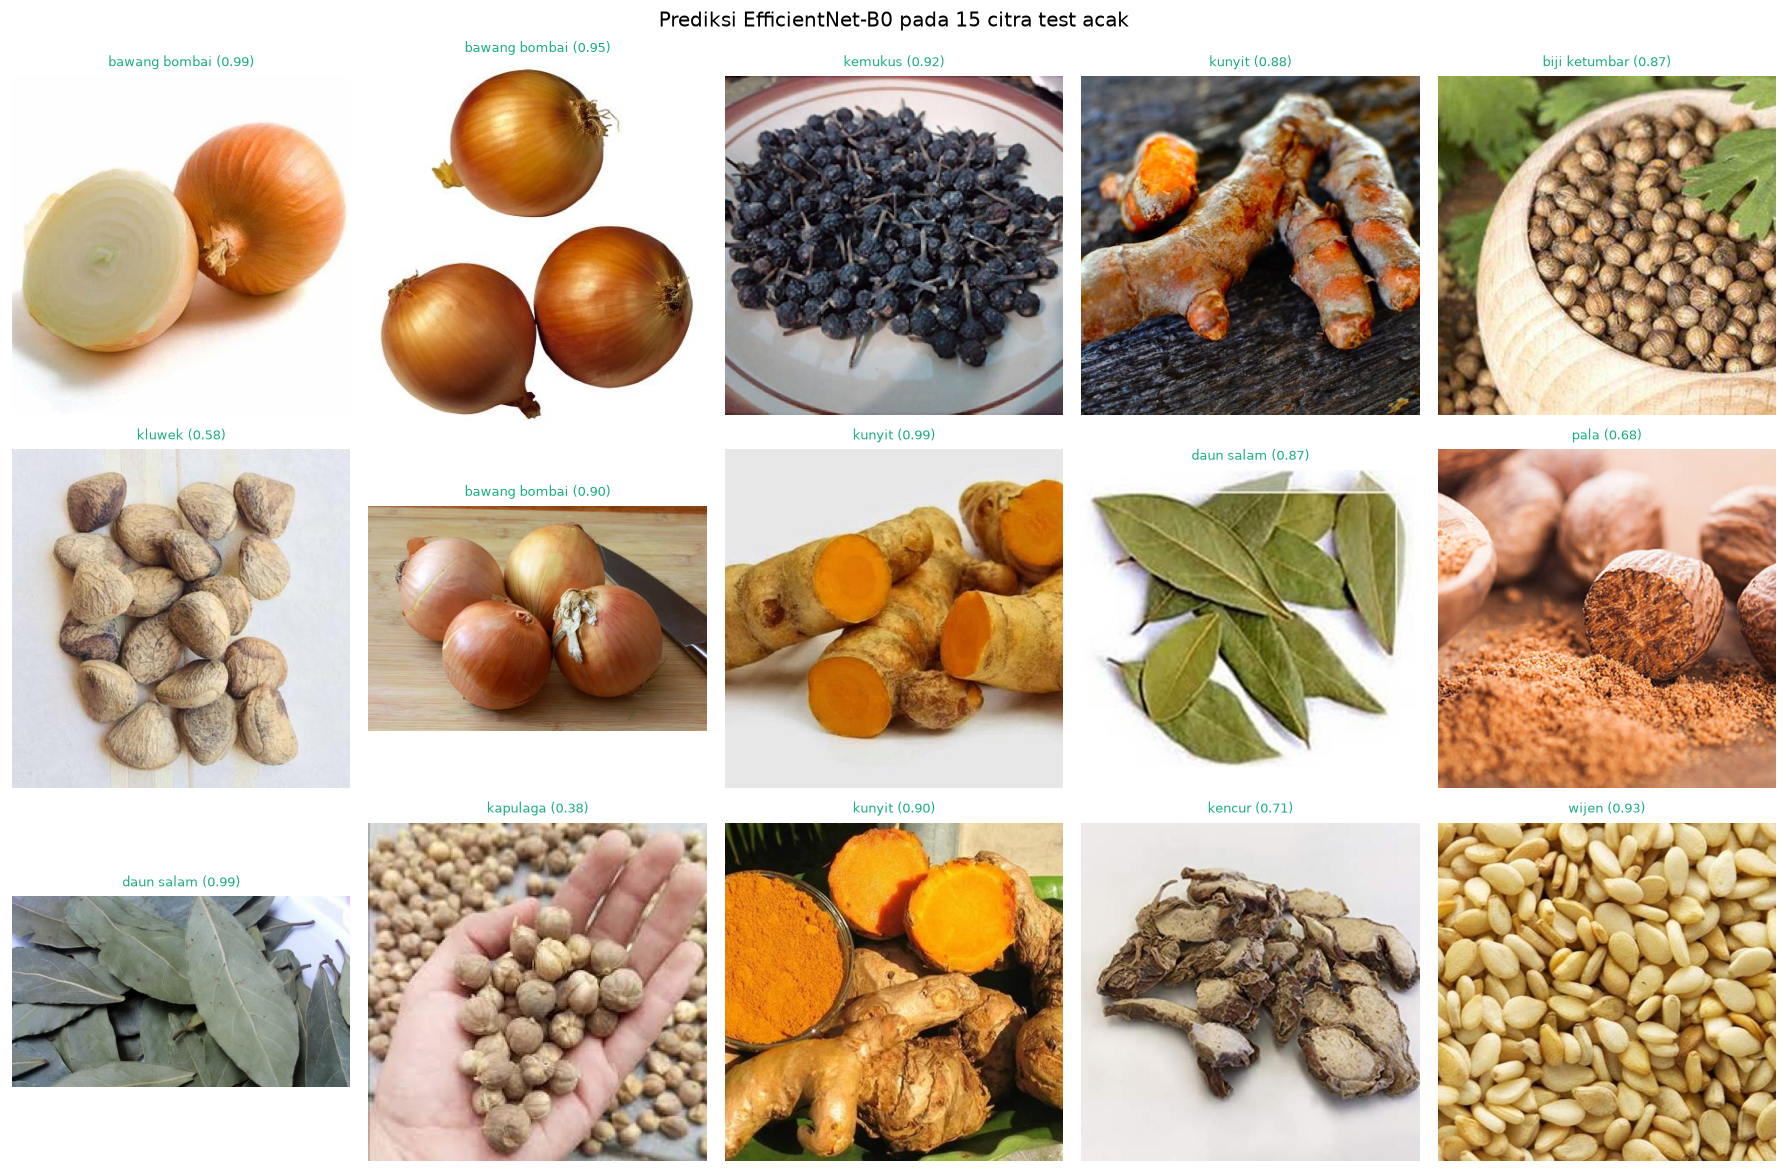

In [11]:
paths = [p for p, _ in ds["test"].samples]

def grid_citra(indeks, judul, nama_file, kolom=5):
    brs = int(np.ceil(len(indeks) / kolom))
    fig, axes = plt.subplots(brs, kolom, figsize=(3 * kolom, 3.35 * brs), squeeze=False)
    for ax, i in zip(axes.ravel(), indeks):
        ax.imshow(Image.open(paths[i]).convert("RGB"))
        ok = preds[i] == trues[i]
        teks = (f"{CLASSES[preds[i]]} ({conf[i]:.2f})" if ok else
                f"prediksi: {CLASSES[preds[i]]} ({conf[i]:.2f})\nasli: {CLASSES[trues[i]]}")
        ax.set_title(teks, fontsize=8, color=C_OK if ok else C_SALAH)
        ax.axis("off")
    for ax in axes.ravel()[len(indeks):]:
        ax.axis("off")
    fig.suptitle(judul)
    plt.tight_layout()
    simpan(fig, nama_file)
    plt.show()

# Sampel acak dari seluruh test set (bukan hanya yang benar) agar representatif
acak = np.random.default_rng(dp.SEED).choice(n_test, 15, replace=False)
print(f"15 sampel acak: {benar[acak].sum()} benar, {(~benar[acak]).sum()} salah")
grid_citra(acak, "Prediksi EfficientNet-B0 pada 15 citra test acak", "prediksi_acak")

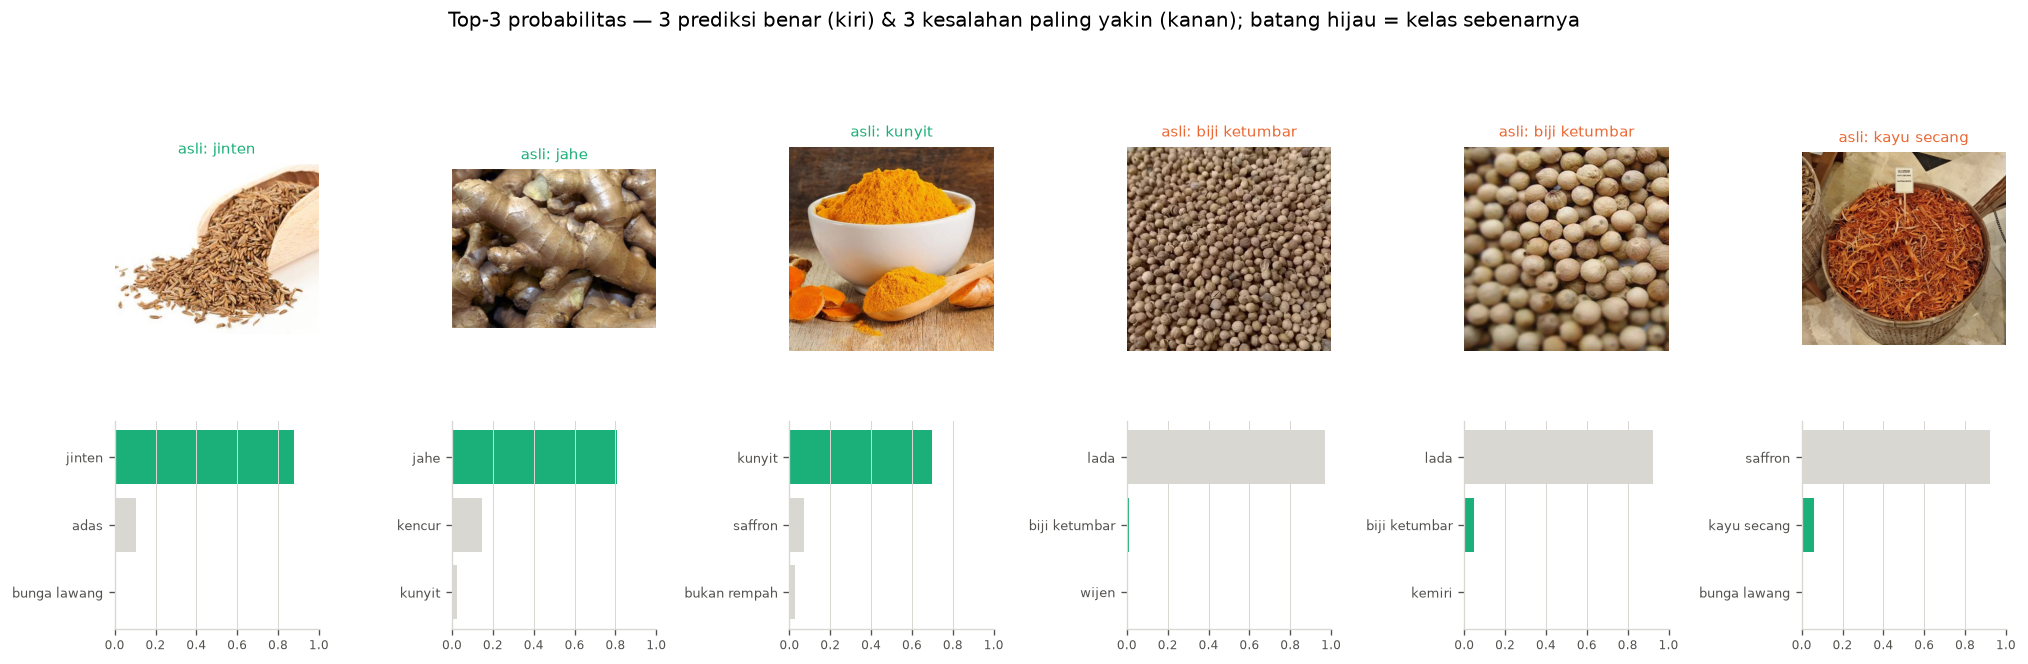

In [12]:
# Top-3 probabilitas: menunjukkan alternatif yang "dipertimbangkan" model
salah_idx = np.where(~benar)[0]
contoh = list(np.random.default_rng(1).choice(np.where(benar)[0], 3, replace=False)) + \
         list(salah_idx[np.argsort(-conf[salah_idx])][:3])

fig, axes = plt.subplots(2, 6, figsize=(17, 5.6), gridspec_kw={"height_ratios": [3, 1.6]})
for k, i in enumerate(contoh):
    ok = preds[i] == trues[i]
    axes[0, k].imshow(Image.open(paths[i]).convert("RGB"))
    axes[0, k].set_title(f"asli: {CLASSES[trues[i]]}", fontsize=9, color=C_OK if ok else C_SALAH)
    axes[0, k].axis("off")
    top = np.argsort(-probs[i])[:3][::-1]
    warna = [C_OK if t == trues[i] else C_GRID for t in top]
    axes[1, k].barh(range(3), probs[i][top], color=warna)
    axes[1, k].set_yticks(range(3))
    axes[1, k].set_yticklabels([CLASSES[t] for t in top], fontsize=8)
    axes[1, k].set_xlim(0, 1)
    axes[1, k].grid(axis="y", visible=False)
    axes[1, k].tick_params(axis="x", labelsize=7)
fig.suptitle("Top-3 probabilitas — 3 prediksi benar (kiri) & 3 kesalahan paling yakin (kanan); "
             "batang hijau = kelas sebenarnya")
plt.tight_layout()
simpan(fig, "top3_probabilitas")
plt.show()

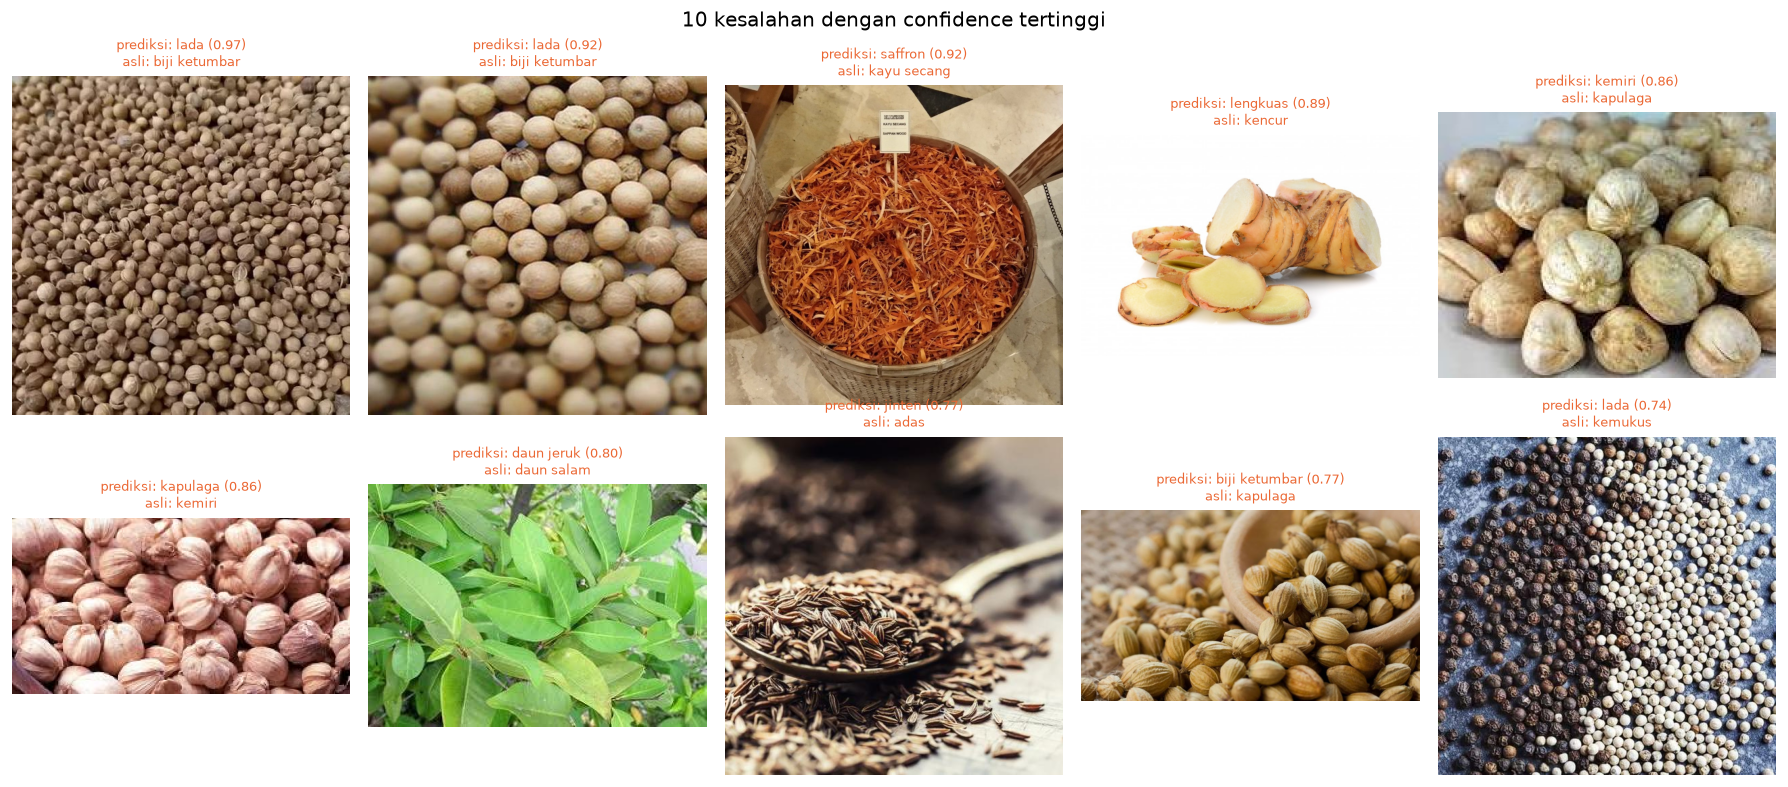

Kesalahan dengan confidence tinggi layak dicek manual: bisa jadi labelnya keliru di dataset,
atau objeknya memang nyaris identik secara visual dengan kelas yang diprediksi.


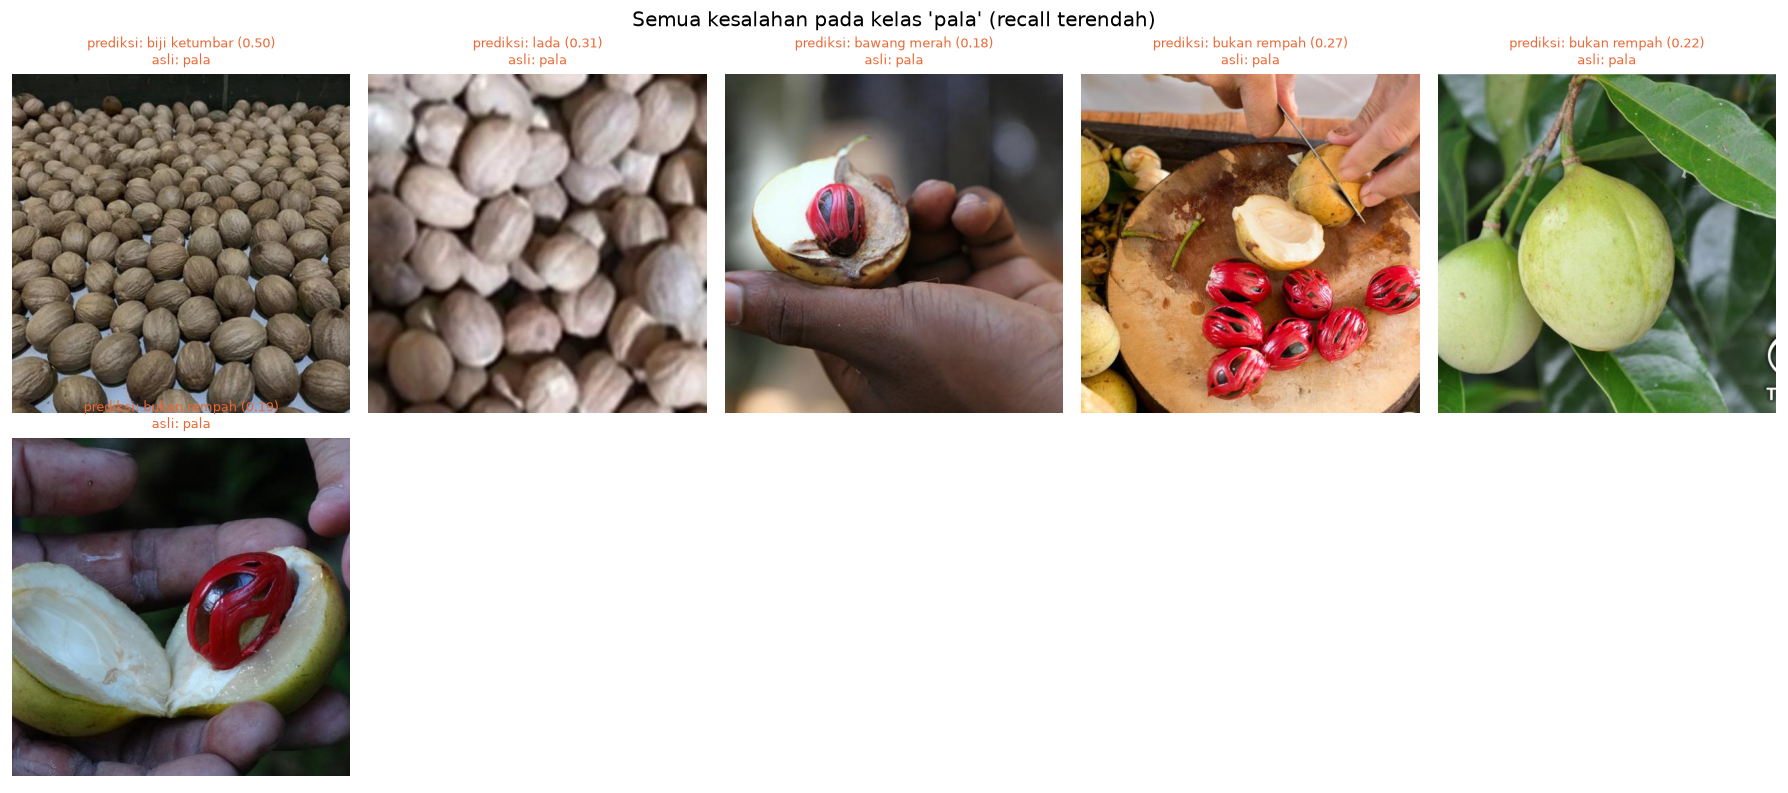

In [13]:
paling_yakin = salah_idx[np.argsort(-conf[salah_idx])][:10]
grid_citra(paling_yakin, "10 kesalahan dengan confidence tertinggi", "kesalahan_paling_yakin")
print("Kesalahan dengan confidence tinggi layak dicek manual: bisa jadi labelnya keliru di dataset,")
print("atau objeknya memang nyaris identik secara visual dengan kelas yang diprediksi.")

# Kelas dengan recall terendah: lihat semua citranya yang salah
kelas_lemah = pk.sort_values("recall").iloc[0]["kelas"]
i_lemah = [i for i in salah_idx if CLASSES[trues[i]] == kelas_lemah]
grid_citra(i_lemah, f"Semua kesalahan pada kelas '{kelas_lemah}' (recall terendah)",
           "kesalahan_kelas_terlemah")

## 8. Efisiensi Komputasi

In [14]:
info = tr.count_parameters(model)
infer = tr.measure_inference(model, DEVICE, batch_size=CONFIG.batch_size)
infer1 = tr.measure_inference(model, DEVICE, batch_size=1)
t_train = hist["train_time_s"].sum() + hist["val_time_s"].sum()

eff = pd.DataFrame([
    ("Jumlah parameter", f"{info['total_params']:,} ({info['total_params']/1e6:.2f} M)"),
    ("Ukuran model (float32)", f"{info['size_mb']:.1f} MB"),
    ("Waktu training total", f"{t_train/60:.1f} menit ({len(hist)} epoch)"),
    ("Rata-rata waktu/epoch", f"{hist['train_time_s'].mean():.0f} s train + {hist['val_time_s'].mean():.0f} s val"),
    (f"Latensi (batch {CONFIG.batch_size})", f"{infer['latency_ms_per_batch']:.1f} ms/batch "
                                             f"= {infer['latency_ms_per_image']:.2f} ms/citra"),
    ("Latensi (batch 1, satu citra)", f"{infer1['latency_ms_per_batch']:.2f} ms"),
    ("Throughput", f"{infer['throughput_img_per_s']:.0f} citra/detik"),
    ("Device", f"{DEVICE}"),
], columns=["metrik", "nilai"])
print(eff.to_string(index=False))
print("\nBatch 1 lebih lambat per citra karena GPU tidak terisi penuh — angka ini yang relevan untuk")
print("aplikasi yang memproses satu foto setiap kali (misalnya aplikasi kamera).")

                       metrik                          nilai
             Jumlah parameter             4,047,259 (4.05 M)
       Ukuran model (float32)                        16.2 MB
         Waktu training total           27.0 menit (5 epoch)
        Rata-rata waktu/epoch         309 s train + 15 s val
           Latensi (batch 32) 108.6 ms/batch = 3.40 ms/citra
Latensi (batch 1, satu citra)                       10.57 ms
                   Throughput                295 citra/detik
                       Device                            mps

Batch 1 lebih lambat per citra karena GPU tidak terisi penuh — angka ini yang relevan untuk
aplikasi yang memproses satu foto setiap kali (misalnya aplikasi kamera).


## 9. Ringkasan Evaluasi

Sel ini merangkum angka-angka di atas sebagai bahan laporan. Interpretasi (*mengapa* model berperilaku
demikian) tetap perlu ditulis sendiri.

In [15]:
ci_i = ci.set_index("metrik")
mt = metrik["test"]
print(f"RINGKASAN EVALUASI — {MODEL_NAME}")
print("-" * 72)
print(f"- Akurasi test {mt['accuracy']:.2%} (95% CI {ci_i.loc['accuracy', 'ci_95_bawah']:.1%}–"
      f"{ci_i.loc['accuracy', 'ci_95_atas']:.1%}), macro-F1 {mt['f1_macro']:.4f} "
      f"(95% CI {ci_i.loc['f1_macro', 'ci_95_bawah']:.3f}–{ci_i.loc['f1_macro', 'ci_95_atas']:.3f}), "
      f"top-5 {mt['top5_accuracy']:.2%}.")
print(f"- Precision macro {mt['precision_macro']:.4f}, recall macro {mt['recall_macro']:.4f}.")
print(f"- {int(mt['n_salah'])} dari {int(mt['n_citra'])} citra test salah klasifikasi.")
print(f"- Test vs validation: {metrik.loc['accuracy', 'selisih (test-val)']:+.4f} akurasi.")
print(f"- Training: {len(hist)} epoch, epoch terbaik {best_ep}, gap train-val akurasi "
      f"{hb['train_acc'] - hb['val_acc']:+.3f}"
      + (" -> belum konvergen penuh." if best_ep == len(hist) else "."))
print(f"- Kelas terlemah: " + ", ".join(f"{r.kelas} (F1 {r.f1:.2f})" for r in pk.head(3).itertuples()))
print(f"- Kelas sempurna (F1 = 1.00): {', '.join(per_kelas.loc[per_kelas['f1'] == 1, 'kelas']) or '-'}")
print(f"- Paling sering tertukar: "
      + "; ".join(f"{r.sebenarnya}->{r.diprediksi} ({r.n})" for r in konfusi.head(4).itertuples()))
print(f"- Korelasi jumlah data train vs F1: r = {r_data:.2f}")
print(f"- Kalibrasi: ECE {ece:.3f}; confidence rata-rata {conf[benar].mean():.2f} saat benar vs "
      f"{conf[~benar].mean():.2f} saat salah.")
print(f"- Efisiensi: {info['total_params']/1e6:.2f} M parameter, {info['size_mb']:.1f} MB, "
      f"{infer['latency_ms_per_image']:.2f} ms/citra (batch {CONFIG.batch_size}) di {DEVICE}.")
print("-" * 72)
print(f"Grafik & tabel tersimpan di: {OUT_DIR}")
for f in sorted(OUT_DIR.iterdir()):
    print(f"  {f.name}")

RINGKASAN EVALUASI — efficientnet_b0
------------------------------------------------------------------------
- Akurasi test 94.03% (95% CI 92.5%–95.6%), macro-F1 0.9394 (95% CI 0.923–0.954), top-5 99.23%.
- Precision macro 0.9412, recall macro 0.9402.
- 54 dari 905 citra test salah klasifikasi.
- Test vs validation: +0.0177 akurasi.
- Training: 5 epoch, epoch terbaik 5, gap train-val akurasi -0.006 -> belum konvergen penuh.
- Kelas terlemah: pala (F1 0.85), biji ketumbar (F1 0.85), kapulaga (F1 0.85)
- Kelas sempurna (F1 = 1.00): bawang bombai, kayu manis, serai
- Paling sering tertukar: adas->jinten (3); kapulaga->biji ketumbar (3); biji ketumbar->lada (3); pala->bukan rempah (3)
- Korelasi jumlah data train vs F1: r = 0.19
- Kalibrasi: ECE 0.087; confidence rata-rata 0.87 saat benar vs 0.53 saat salah.
- Efisiensi: 4.05 M parameter, 16.2 MB, 3.40 ms/citra (batch 32) di mps.
------------------------------------------------------------------------
Grafik & tabel tersimpan di: /Users/a